# Digital Detective: Feature Extraction Challenge
This interactive notebook allows you to run computer vision algorithms (ORB) to extract and match visual features between images, simulating a digital detective searching for clues.

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Helper function to display images properly in Jupyter/Colab
def show_img(title, img):
    plt.figure(figsize=(12, 8))
    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

## Step 1: Load and Prepare Images
Make sure you have uploaded `Cup.jpeg` and `Table.jpeg` to your Colab environment or local directory before running this cell.

Images successfully loaded and converted to grayscale.


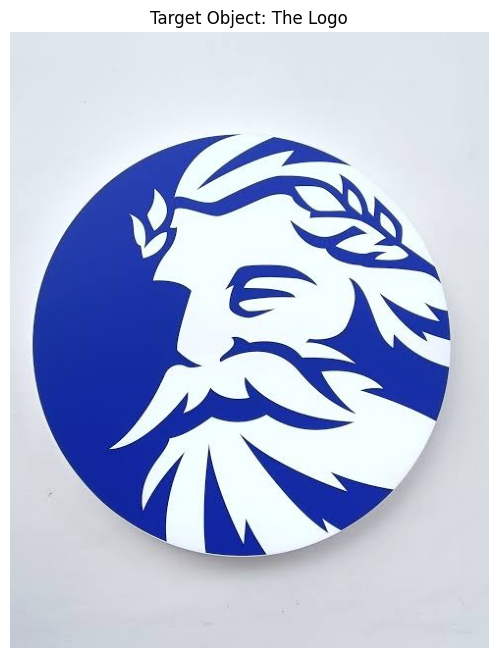

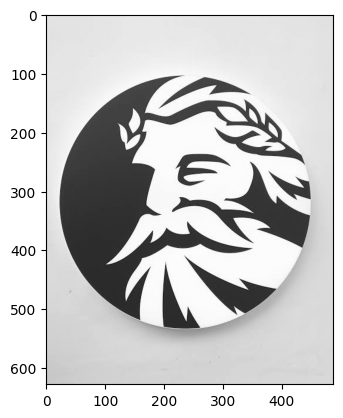

In [ ]:
# Load the target image and the scene
img_logo = cv2.imread('logo.jpg')
img_shop = cv2.imread('shop.jpg')

if img_cup is None or img_table is None:
    print("Error: Could not load images. Please ensure logo.jpg and shop.jpg are uploaded to the current directory.")
else:
    # Convert to grayscale (feature extraction works best on intensity, not color)
    gray_logo = cv2.cvtColor(img_logo, cv2.COLOR_BGR2GRAY)
    gray_shop = cv2.cvtColor(img_shop, cv2.COLOR_BGR2GRAY)
    print("Images successfully loaded and converted to grayscale.")
    show_img("Target Object: The Logo", img_logo)
    plt.imshow(gray_logo, cmap='gray')

## Step 2: Extract Features using ORB
Here, the computer acts as the detective, identifying keypoints (distinctive corners and edges) and calculating their mathematical descriptors.

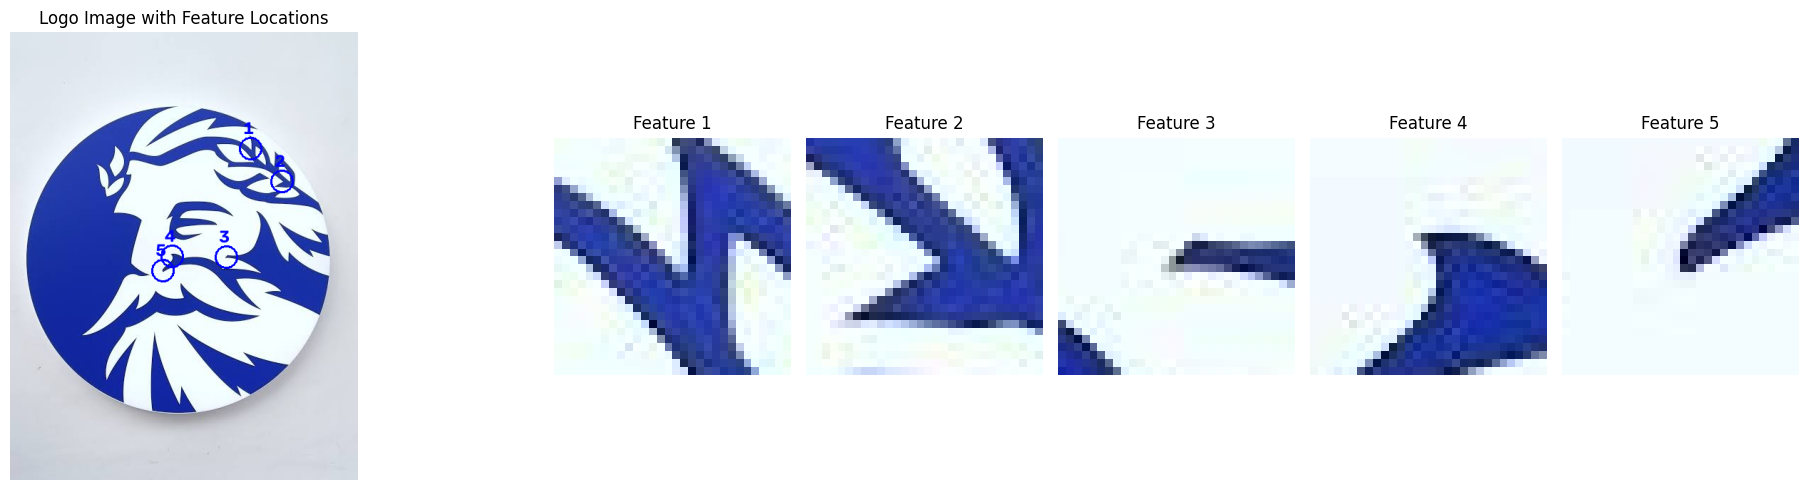

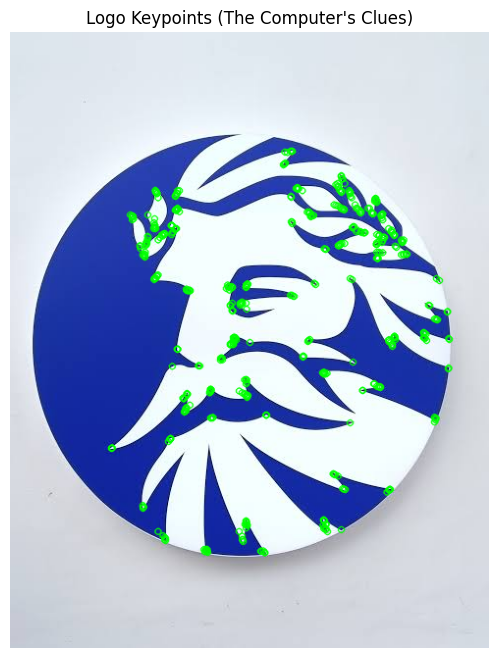

In [ ]:
# Initialize the ORB detector (finding up to 500 features)
orb = cv2.ORB_create(nfeatures=500)

# Detect keypoints and compute descriptors
kp_logo, des_logo = orb.detectAndCompute(gray_logo, None)
kp_shop, des_shop = orb.detectAndCompute(gray_shop, None)


# 1. Setup a figure with 6 subplots (1 large for the main image, 5 small for the patches)
fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})

# 2. Create a copy of the original cup image to draw annotations on
img_logo_annotated = img_logo.copy()
offset = 15 # 15 pixels in every direction creates a 30x30 patch

# 3. Loop through the first 5 detected keypoints
for i in range(5):
    kp = kp_logo[i]
    x, y = int(kp.pt[0]), int(kp.pt[1])

    # Draw a numbered blue circle on the main image at the keypoint's exact location
    cv2.circle(img_logo_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(img_logo_annotated, str(i+1), (x - 10, y - 20),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    # Crop the pixel patch, using min/max to prevent errors if a point is near the image edge
    patch = img_logo[max(0, y - offset) : min(img_logo.shape[0], y + offset),
                    max(0, x - offset) : min(img_logo.shape[1], x + offset)]

    # Display the cropped patch in its respective subplot
    axes[i+1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i+1].set_title(f"Feature {i+1}")
    axes[i+1].axis('off')

# 4. Display the annotated main image in the first subplot
axes[0].imshow(cv2.cvtColor(img_logo_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Logo Image with Feature Locations")
axes[0].axis('off')

plt.tight_layout()
plt.show()


# Visualize the keypoints found on the cup
img_logo_kp = cv2.drawKeypoints(img_logo, kp_logo, None, color=(0, 255, 0), flags=0)
show_img("Logo Keypoints (The Computer's Clues)", img_logo_kp)

## Step 3 & 4: Match Features and Analyze the Results
The computer now compares the descriptors from the cup against the descriptors found in the cluttered scene to find matches.

Total features matched: 125


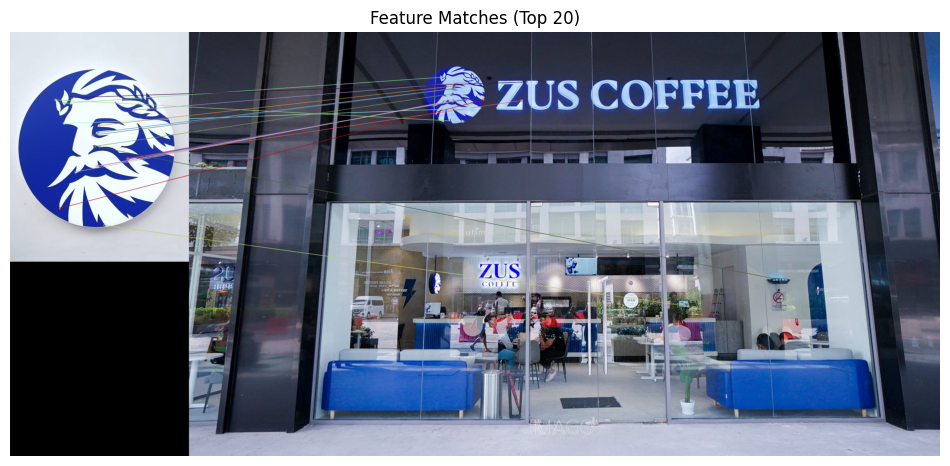

In [ ]:
# Create a Brute-Force Matcher to compare descriptor distances (Hamming distance for ORB)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors between the logo and the shop
matches = bf.match(des_logo, des_shop)

# Sort the matches based on how similar they are (lower distance = better match)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Total features matched: {len(matches)}")

# Draw the top 20 best matches to avoid visual clutter
img_matches = cv2.drawMatches(
    img_logo, kp_logo,
    img_shop, kp_shop,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_img("Feature Matches (Top 20)", img_matches)

# Reflection & Discussion

1.Feature Effectiveness

Sharp blue/white corner edges at the hair and beard are high contrast, making them unique and easy to match.


2.Ambiguous Features

Features 3 & 5 which are thin diagonal edges look similar to building/glass edges, causing wrong matches.


3.Robustness Challenge

In term of rotation, ORB handles it well. In term of lighting, the difference of the glowing shop sign and the flat logo causes some mismatched lines.